# 11-9. 부분 로그변환 최종모형 OLS

## 분석 목적

GTX-A 개통 전후 250m 격자별 광역버스 승차인원 변화량을 설명한다.

- **분석 단위:** 공급구조가 유지된 250m 격자 126개
- **종속변수:** 2025-11-06 승차인원 − 2024-10-17 승차인원
- **추정법:** OLS
- **표준오차:** HC3 이분산 강건 표준오차
- **최종 함수형태:** 보행시간과 건축물 연면적에만 `log(1+x)` 적용

## 부분 로그변환을 선택한 이유

1. **GTX역 보행시간**은 오른쪽으로 치우치고 범위가 넓다. 가까운 구간의 10분 차이가 매우 먼 구간의 10분 차이보다 접근성에 더 큰 영향을 준다는 체감효과를 반영하기 위해 로그변환한다.
2. **건축물 연면적**은 일부 대규모 격자의 값이 크다. 절대면적 증가보다 비례적 규모 증가를 표현하고 큰 값의 영향력을 완화하기 위해 로그변환한다.
3. **20~50대 인구**는 왜도가 크지 않고 로그변환에 따른 적합도 개선도 없어 원 단위를 유지한다.
4. **주거지역 비율·GTX 경쟁 목적지 비율**은 0~100%로 제한된 변수다. 1%p 증가의 해석을 유지하고, 특히 경쟁 목적지 비율은 0값이 많아 로그변환하지 않는다.
5. **평균 버스 통행시간·IC 도로거리**는 치우침이 크지 않고 1분·1km 증가의 해석이 명확하므로 원 단위를 유지한다.

> 로그변환은 유의성을 높이기 위한 사후 선택이 아니라 변수 분포, 체감효과에 관한 이론 및 해석 가능성을 기준으로 적용한다.

In [1]:
# 프로젝트 루트(UROP) 자동 탐색 — 절대경로 없이 어느 컴퓨터에서도 동작
import sys
from pathlib import Path
UROP_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config.py').is_file() and (p / 'code').is_dir())
for _d in [UROP_ROOT, *sorted(d for d in (UROP_ROOT / 'code').rglob('*') if d.is_dir() and d.name != '__pycache__')]:
    if str(_d) not in sys.path:
        sys.path.append(str(_d))

from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from IPython.display import display

# 실행 위치가 저장소 루트 또는 analysis 폴더인 경우 모두 지원
PROJECT = UROP_ROOT
PROCESSED = PROJECT / 'data' / 'processed' / 'gtx_a'

# seaborn 테마를 먼저 적용한 뒤 한글 글꼴을 마지막에 지정한다.
sns.set_theme(style='whitegrid')
font_candidates = [
    '/System/Library/Fonts/AppleSDGothicNeo.ttc',
    '/System/Library/Fonts/Supplemental/AppleGothic.ttf',
    '/Library/Fonts/Arial Unicode.ttf',
    r'C:\Windows\Fonts\malgun.ttf',
]
korean_font_name = None
for font_path in font_candidates:
    if Path(font_path).exists():
        fm.fontManager.addfont(font_path)
        korean_font_name = fm.FontProperties(fname=font_path).get_name()
        break
if korean_font_name is None:
    raise FileNotFoundError('사용 가능한 한글 글꼴을 찾지 못했습니다.')
plt.rcParams.update({
    'font.family': korean_font_name,
    'font.sans-serif': [korean_font_name],
    'axes.unicode_minus': False,
})
print('그래프 한글 글꼴:', korean_font_name)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

print('프로젝트:', PROJECT)
print('데이터:', PROCESSED)

그래프 한글 글꼴: Apple SD Gothic Neo
프로젝트: /Users/keumkyounghoon/Desktop/Gachon/3-2/UROP/github_2026-UROP/gtx_a_bus_analysis
데이터: /Users/keumkyounghoon/Desktop/Gachon/3-2/UROP/github_2026-UROP/gtx_a_bus_analysis/data/processed


## 1. 데이터 결합과 분석표본 확인

In [2]:
def read_one(pattern):
    paths = sorted(PROCESSED.glob(pattern))
    if len(paths) != 1:
        raise FileNotFoundError(f'{pattern}: 파일 {len(paths)}개 발견')
    return pd.read_csv(paths[0], encoding='utf-8-sig', low_memory=False)

base = read_one('18_*.csv')
extra = read_one('18-1_*.csv')
land = read_one('19_*.csv')
floor = read_one('24_*.csv')

ID = '셀 ID'
RESIDENTIAL = '주거지역 비율(%)'
FLOOR = '2024년 건축물 연면적(천㎡)'
for frame in [base, extra, land, floor]:
    frame[ID] = pd.to_numeric(frame[ID], errors='coerce').astype('Int64')

data = (
    base
    .merge(extra[[ID, 'bus_time_mean']], on=ID, how='left', validate='one_to_one')
    .merge(land[[ID, RESIDENTIAL]], on=ID, how='left', validate='one_to_one')
    .merge(floor[[ID, FLOOR]], on=ID, how='left', validate='one_to_one')
)

raw_variables = [
    'walk_min', 'pop_20_50', FLOOR, RESIDENTIAL,
    'competing_share', 'bus_time_mean', 'ic_access'
]
for column in ['change_all'] + raw_variables:
    data[column] = pd.to_numeric(data[column], errors='coerce')

print('결합 격자 수:', len(data))
print('역 권역별 격자 수:')
display(data['nearest_station'].value_counts().rename('격자 수').to_frame())
print('주요 변수 결측치:')
display(data[['change_all'] + raw_variables].isna().sum().rename('결측 수').to_frame())

결합 격자 수: 126
역 권역별 격자 수:
주요 변수 결측치:


,격자 수
nearest_station,
운정중앙,63
대곡,37
킨텍스,26


,결측 수
change_all,0
walk_min,0
pop_20_50,0
2024년 건축물 연면적(천㎡),0
주거지역 비율(%),0
competing_share,0
bus_time_mean,0
ic_access,0


## 2. 변수별 분포와 로그변환 근거 확인

왜도 절댓값, 값의 범위, 0값 비율을 함께 확인한다. 로그변환 여부는 왜도만으로 정하지 않고 변수의 의미와 한계효과의 형태를 함께 고려한다.

In [3]:
distribution_labels = {
    'walk_min': 'GTX역 보행시간(분)',
    'pop_20_50': '20~50대 인구(명)',
    FLOOR: FLOOR,
    RESIDENTIAL: RESIDENTIAL,
    'competing_share': 'GTX 경쟁 목적지 비율(%)',
    'bus_time_mean': '평균 버스 통행시간(분)',
    'ic_access': 'IC 도로거리(km)',
}
rows = []
for variable in raw_variables:
    x = data[variable].dropna()
    rows.append({
        '변수': distribution_labels[variable], '표본 수': len(x),
        '최솟값': x.min(), 'Q1': x.quantile(.25), '중앙값': x.median(),
        '평균': x.mean(), 'Q3': x.quantile(.75), '최댓값': x.max(),
        '왜도': x.skew(), '0값 수': int(x.eq(0).sum()),
        '0값 비율(%)': x.eq(0).mean() * 100,
    })
distribution_table = pd.DataFrame(rows)
display(distribution_table.round(3))

,변수,표본 수,최솟값,Q1,중앙값,평균,Q3,최댓값,왜도,0값 수,0값 비율(%)
0,GTX역 보행시간(분),126,3.553,31.561,47.604,65.925,90.333,259.178,1.602,0,0.000
1,20~50대 인구(명),126,0.000,108.500,551.000,647.111,1068.750,2141.000,0.532,16,12.698
2,2024년 건축물 연면적(천㎡),126,0.000,0.595,2.237,3.752,6.364,14.575,0.934,2,1.587
3,주거지역 비율(%),126,0.000,14.707,70.807,58.392,96.336,100.000,-0.425,21,16.667
4,GTX 경쟁 목적지 비율(%),126,0.000,0.000,0.000,10.872,16.951,100.000,2.427,78,61.905
5,평균 버스 통행시간(분),126,6.400,37.279,40.384,40.656,44.203,79.700,0.593,0,0.000
6,IC 도로거리(km),126,0.319,2.846,4.769,5.108,6.557,11.772,0.675,0,0.000


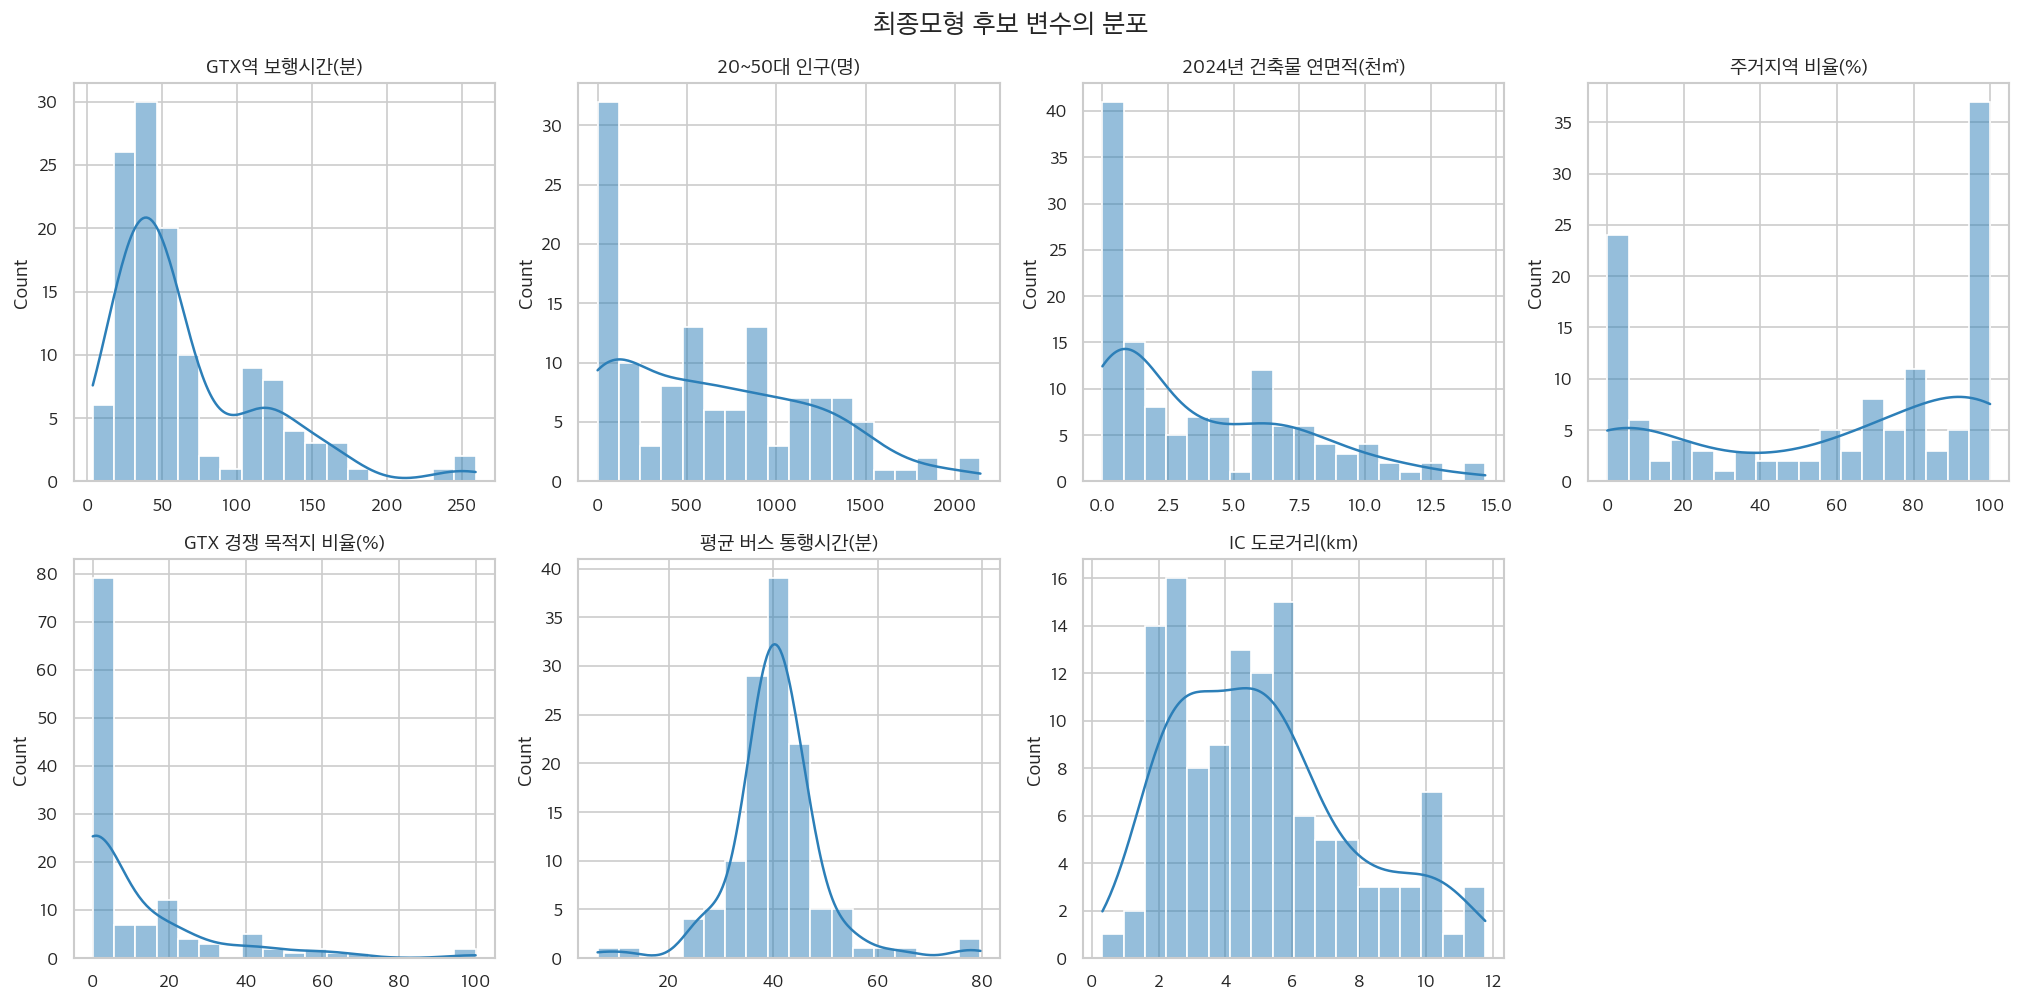

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
for ax, variable in zip(axes.flat, raw_variables):
    sns.histplot(data=data, x=variable, bins=18, kde=True, ax=ax, color='#2C7FB8')
    ax.set_title(distribution_labels[variable])
    ax.set_xlabel('')
axes.flat[-1].axis('off')
fig.suptitle('최종모형 후보 변수의 분포', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. 부분 로그변환과 최종 분석표본

- `log_walk = log(1 + 보행시간)`
- `log_floor = log(1 + 건축물 연면적)`
- 인구와 나머지 변수는 원 단위 유지

`log1p`를 사용하므로 연면적이 0인 격자도 분석에서 탈락하지 않는다.

In [5]:
data['log_walk'] = np.log1p(data['walk_min'])
data['log_floor'] = np.log1p(data[FLOOR])
data['log_pop'] = np.log1p(data['pop_20_50'])  # 함수형태 비교에만 사용

FINAL_FEATURES = [
    'log_walk', 'pop_20_50', 'log_floor', RESIDENTIAL,
    'competing_share', 'bus_time_mean', 'ic_access'
]
LABELS = {
    'log_walk': 'log(1+GTX역 보행시간)',
    'pop_20_50': '20~50대 인구(명)',
    'log_floor': 'log(1+건축물 연면적)',
    RESIDENTIAL: RESIDENTIAL,
    'competing_share': 'GTX 경쟁 목적지 비율(%)',
    'bus_time_mean': '평균 버스 통행시간(분)',
    'ic_access': 'IC 도로거리(km)',
}
sample = data.dropna(subset=['change_all'] + FINAL_FEATURES).copy()
assert len(sample) == 126, f'예상 표본 126개와 다릅니다: {len(sample)}개'
print('최종 분석표본:', len(sample), '개')

최종 분석표본: 126 개


## 4. 함수형태 비교

보행시간·인구·연면적의 원자료/로그 조합 8개를 동일한 표본과 동일한 통제변수로 비교한다. 이 표는 로그변환의 기여를 확인하는 민감도 분석이며, p값만으로 함수형태를 선택하지 않는다.

In [6]:
import itertools
comparison_rows = []
FIXED = [RESIDENTIAL, 'competing_share', 'bus_time_mean', 'ic_access']
for log_walk, log_pop, log_floor in itertools.product([False, True], repeat=3):
    walk_var = 'log_walk' if log_walk else 'walk_min'
    pop_var = 'log_pop' if log_pop else 'pop_20_50'
    floor_var = 'log_floor' if log_floor else FLOOR
    features = [walk_var, pop_var, floor_var] + FIXED
    current = data.dropna(subset=['change_all'] + features)
    X_current = sm.add_constant(current[features], has_constant='add')
    current_fit = sm.OLS(current['change_all'], X_current).fit(cov_type='HC3')
    comparison_rows.append({
        '보행시간': 'log(1+x)' if log_walk else '원자료',
        '인구': 'log(1+x)' if log_pop else '원자료',
        '연면적': 'log(1+x)' if log_floor else '원자료',
        '수정 R²': current_fit.rsquared_adj,
        'AIC': current_fit.aic,
        '보행시간 p값': current_fit.pvalues[walk_var],
        '인구 p값': current_fit.pvalues[pop_var],
        '연면적 p값': current_fit.pvalues[floor_var],
        '주거지역 p값': current_fit.pvalues[RESIDENTIAL],
    })
function_comparison = pd.DataFrame(comparison_rows).sort_values('AIC').reset_index(drop=True)
display(function_comparison.round(4))

,보행시간,인구,연면적,수정 R²,AIC,보행시간 p값,인구 p값,연면적 p값,주거지역 p값
0,log(1+x),원자료,log(1+x),0.3074,1642.4744,0.0000,0.3094,0.0618,0.0249
1,log(1+x),log(1+x),log(1+x),0.3054,1642.8443,0.0000,0.4982,0.0657,0.0256
2,log(1+x),log(1+x),원자료,0.3045,1643.0114,0.0000,0.4291,0.0889,0.0275
3,log(1+x),원자료,원자료,0.3024,1643.3807,0.0000,0.4838,0.0818,0.0316
4,원자료,log(1+x),원자료,0.1996,1660.7017,0.0078,0.2007,0.0781,0.0364
5,원자료,log(1+x),log(1+x),0.1979,1660.9777,0.0085,0.2110,0.0606,0.0312
6,원자료,원자료,log(1+x),0.1885,1662.4370,0.0099,0.6356,0.0583,0.0534
7,원자료,원자료,원자료,0.1856,1662.8844,0.0087,0.8221,0.0722,0.0761


## 5. 최종 OLS 모형(HC3)

\[
egin{aligned}
Change_i = &\;eta_0 + eta_1\log(1+Walk_i) + eta_2Population_i \
&+ eta_3\log(1+FloorArea_i) + eta_4Residential_i \
&+ eta_5Competition_i + eta_6BusTime_i + eta_7ICDistance_i + \epsilon_i
\end{aligned}
\]

변화량이 대부분 음수이므로 양의 보행시간 계수는 **GTX역에서 멀어질수록 변화량이 높고, 반대로 GTX역에 가까울수록 감소폭이 크다**는 뜻이다.

In [7]:
X = sm.add_constant(sample[FINAL_FEATURES].astype(float), has_constant='add')
y = sample['change_all'].astype(float)
final_fit = sm.OLS(y, X).fit(cov_type='HC3')
print(final_fit.summary())

ci = final_fit.conf_int().loc[FINAL_FEATURES]
coefficient_table = pd.DataFrame({
    '변수': [LABELS[v] for v in FINAL_FEATURES],
    '계수(명)': final_fit.params.loc[FINAL_FEATURES].values,
    'HC3 표준오차': final_fit.bse.loc[FINAL_FEATURES].values,
    'z값': final_fit.tvalues.loc[FINAL_FEATURES].values,
    'p값': final_fit.pvalues.loc[FINAL_FEATURES].values,
    '95% CI 하한': ci[0].values,
    '95% CI 상한': ci[1].values,
})
coefficient_table['유의성'] = np.select(
    [coefficient_table['p값'] < .01, coefficient_table['p값'] < .05,
     coefficient_table['p값'] < .10],
    ['***', '**', '*'], default=''
)
display(coefficient_table.round(4))

model_table = pd.DataFrame([{
    '표본 수': int(final_fit.nobs), 'R²': final_fit.rsquared,
    '수정 R²': final_fit.rsquared_adj, '모형 F값': float(final_fit.fvalue),
    '모형 p값': float(final_fit.f_pvalue), 'AIC': final_fit.aic,
    'BIC': final_fit.bic,
}])
display(model_table.round(4))

                            OLS Regression Results                            
Dep. Variable:             change_all   R-squared:                       0.346
Model:                            OLS   Adj. R-squared:                  0.307
Method:                 Least Squares   F-statistic:                     4.971
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           5.91e-05
Time:                        15:11:34   Log-Likelihood:                -813.24
No. Observations:                 126   AIC:                             1642.
Df Residuals:                     118   BIC:                             1665.
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            -683.2513    159.565     

,변수,계수(명),HC3 표준오차,z값,p값,95% CI 하한,95% CI 상한,유의성
0,log(1+GTX역 보행시간),148.8107,32.9488,4.5164,0.0000,84.2322,213.3892,***
1,20~50대 인구(명),0.0370,0.0364,1.0166,0.3094,-0.0344,0.1084,
2,log(1+건축물 연면적),-72.1137,38.6079,-1.8679,0.0618,-147.7837,3.5563,*
3,주거지역 비율(%),1.6974,0.7567,2.2431,0.0249,0.2142,3.1806,**
4,GTX 경쟁 목적지 비율(%),-1.1164,0.6514,-1.7138,0.0866,-2.3931,0.1603,*
5,평균 버스 통행시간(분),-0.1797,1.0542,-0.1705,0.8646,-2.2459,1.8864,
6,IC 도로거리(km),-3.2943,3.8673,-0.8518,0.3943,-10.8740,4.2854,


,표본 수,R²,수정 R²,모형 F값,모형 p값,AIC,BIC
0,126,0.3462,0.3074,4.9706,0.0001,1642.4744,1665.1646


### 로그계수의 해석

종속변수는 원 단위(명), 일부 독립변수만 로그이므로 로그변수의 계수는 수준–로그 관계다. 독립변수가 두 배가 될 때 변화량 차이는 대략 `계수 × ln(2)`로 계산한다. `log(1+x)`를 사용했으므로 값이 매우 작을 때는 정확한 예측차이를 별도로 계산해야 한다.

In [8]:
doubling_table = pd.DataFrame([
    {
        '변수': 'GTX역 보행시간',
        '두 배 증가 시 변화량 차이(근사, 명)': final_fit.params['log_walk'] * np.log(2),
    },
    {
        '변수': '건축물 연면적',
        '두 배 증가 시 변화량 차이(근사, 명)': final_fit.params['log_floor'] * np.log(2),
    },
])
display(doubling_table.round(2))

,변수,"두 배 증가 시 변화량 차이(근사, 명)"
0,GTX역 보행시간,103.15
1,건축물 연면적,-49.99


## 6. 다중공선성 진단(VIF)

일반적으로 VIF가 5 이상이면 주의하고 10 이상이면 심각한 다중공선성을 의심한다. 상수항의 VIF는 해석 대상에서 제외한다.

In [9]:
vif_table = pd.DataFrame({
    '변수': [LABELS[v] for v in FINAL_FEATURES],
    'VIF': [
        variance_inflation_factor(X.to_numpy(), X.columns.get_loc(v))
        for v in FINAL_FEATURES
    ],
}).sort_values('VIF', ascending=False).reset_index(drop=True)
display(vif_table.round(3))
print('최대 VIF:', round(vif_table['VIF'].max(), 3))

최대 VIF: 2.57


,변수,VIF
0,20~50대 인구(명),2.570
1,log(1+건축물 연면적),2.216
2,주거지역 비율(%),1.790
3,log(1+GTX역 보행시간),1.663
4,IC 도로거리(km),1.424
5,GTX 경쟁 목적지 비율(%),1.127
6,평균 버스 통행시간(분),1.048


## 7. 잔차·함수형태·영향력 진단

- **Breusch–Pagan:** 이분산 여부. 이분산에 대응하기 위해 최종 추론에는 HC3 표준오차를 사용한다.
- **Jarque–Bera:** 잔차 정규성 진단. 표본이 작고 극단값이 있으므로 함께 보고한다.
- **Ramsey RESET:** 누락된 비선형 함수형태 가능성을 진단한다.
- **Cook's distance:** 특정 격자가 추정치를 과도하게 좌우하는지 확인한다. 삭제 기준이 아니라 현장·공간 확인 대상 선정에 사용한다.

In [10]:
# 진단통계 계산을 위한 일반 OLS 적합값·잔차(계수와 예측값은 HC3 모형과 동일)
plain_fit = sm.OLS(y, X).fit()
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(plain_fit.resid, X)
jb = jarque_bera(plain_fit.resid)
reset = linear_reset(plain_fit, power=2, use_f=True)

diagnostic_tests = pd.DataFrame([
    {'검정': 'Breusch–Pagan', '통계량': bp_lm, 'p값': bp_lm_p, '판단': '이분산 가능' if bp_lm_p < .05 else '뚜렷한 이분산 없음'},
    {'검정': 'Jarque–Bera', '통계량': jb.statistic, 'p값': jb.pvalue, '판단': '잔차 비정규' if jb.pvalue < .05 else '정규성 기각 안 됨'},
    {'검정': 'Ramsey RESET', '통계량': float(reset.fvalue), 'p값': float(reset.pvalue), '판단': '추가 함수형태 검토 필요' if reset.pvalue < .05 else '뚜렷한 설정 오류 없음'},
])
display(diagnostic_tests.round(6))

influence = OLSInfluence(plain_fit)
diagnostic = sample[[ID, 'nearest_station', 'change_all', 'walk_min', FLOOR]].copy()
diagnostic['적합값'] = plain_fit.fittedvalues
diagnostic['잔차'] = plain_fit.resid
diagnostic['표준화 잔차'] = influence.resid_studentized_internal
diagnostic["Cook's distance"] = influence.cooks_distance[0]
cook_threshold = 4 / len(diagnostic)
print(f"Cook's distance 참고선 4/N = {cook_threshold:.4f}")
cook_exceed_count = int((diagnostic["Cook's distance"] > cook_threshold).sum())
print(f"참고선 초과 격자 수 = {cook_exceed_count}개")
display(diagnostic.nlargest(10, "Cook's distance").round(4))

Cook's distance 참고선 4/N = 0.0317
참고선 초과 격자 수 = 6개


,검정,통계량,p값,판단
0,Breusch–Pagan,19.025531,0.008108,이분산 가능
1,Jarque–Bera,1403.760696,0.000000,잔차 비정규
2,Ramsey RESET,19.702662,0.000021,추가 함수형태 검토 필요


,셀 ID,nearest_station,change_all,walk_min,2024년 건축물 연면적(천㎡),적합값,잔차,표준화 잔차,Cook's distance
35,4934,킨텍스,-1382.0,20.1800,8.0632,-351.4653,-1030.5347,-6.7134,0.4012
61,8868,킨텍스,-770.0,7.9233,0.0000,-371.0692,-398.9308,-2.7013,0.1435
75,10274,킨텍스,-841.0,20.1900,12.1674,-421.5913,-419.4087,-2.7930,0.1164
81,10778,운정중앙,-742.0,31.3717,5.8100,-296.4188,-445.5812,-2.8900,0.0645
78,10528,운정중앙,-112.0,32.2883,12.5699,-338.6882,226.6882,1.5269,0.0423
113,13793,킨텍스,-611.0,26.7667,9.8900,-205.9459,-405.0541,-2.6021,0.0353
118,14148,운정중앙,-3.0,117.2683,0.1954,-135.3731,132.3731,0.9333,0.0277
31,4205,킨텍스,-10.0,47.3700,14.4295,-241.4931,231.4931,1.5183,0.0247
73,10111,운정중앙,-2.0,250.8317,1.4347,194.0286,-196.0286,-1.2954,0.0215
99,12580,운정중앙,-2.0,43.2850,6.2279,-111.7095,109.7095,0.7613,0.0156


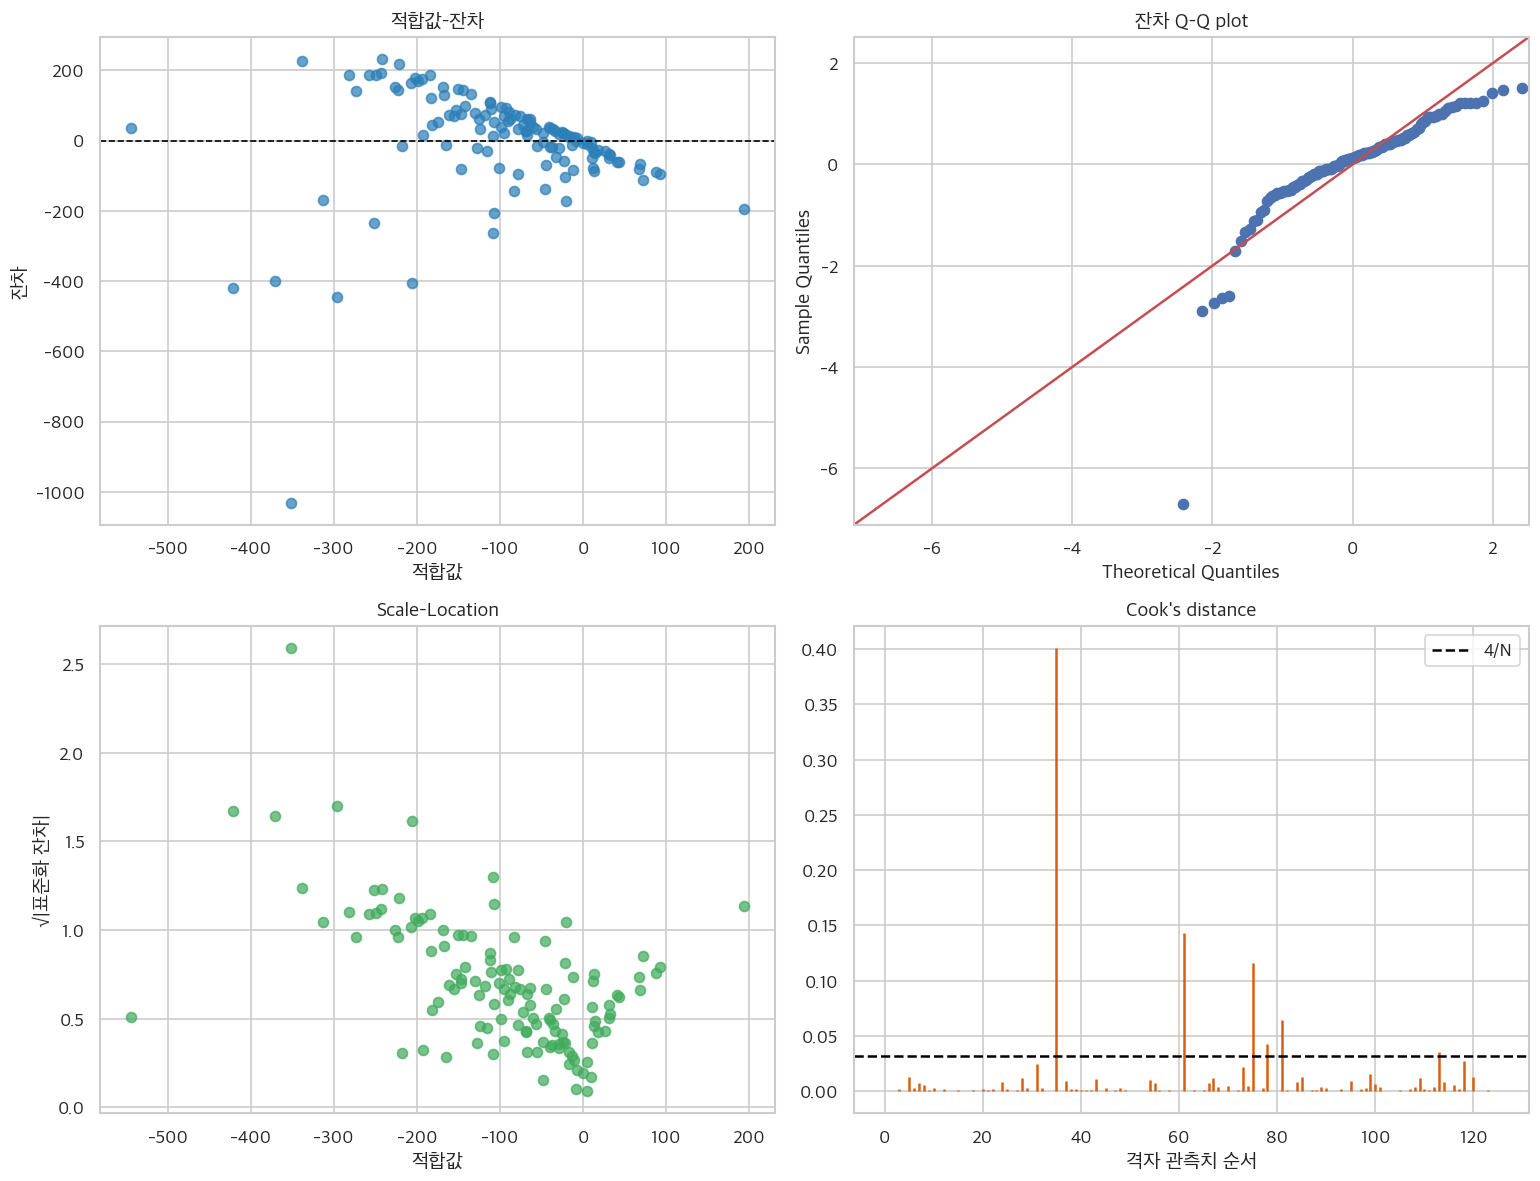

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].scatter(plain_fit.fittedvalues, plain_fit.resid, alpha=.72, color='#2C7FB8')
axes[0, 0].axhline(0, color='black', linestyle='--', linewidth=1)
axes[0, 0].set_title('적합값–잔차')
axes[0, 0].set_xlabel('적합값'); axes[0, 0].set_ylabel('잔차')

sm.qqplot(plain_fit.resid, line='45', fit=True, ax=axes[0, 1])
axes[0, 1].set_title('잔차 Q–Q plot')

sqrt_abs = np.sqrt(np.abs(influence.resid_studentized_internal))
axes[1, 0].scatter(plain_fit.fittedvalues, sqrt_abs, alpha=.72, color='#41AB5D')
axes[1, 0].set_title('Scale–Location')
axes[1, 0].set_xlabel('적합값'); axes[1, 0].set_ylabel('√|표준화 잔차|')

axes[1, 1].stem(np.arange(len(diagnostic)), diagnostic["Cook's distance"], linefmt='#D95F0E', markerfmt=' ', basefmt=' ')
axes[1, 1].axhline(cook_threshold, color='black', linestyle='--', label='4/N')
axes[1, 1].set_title("Cook's distance")
axes[1, 1].set_xlabel('격자 관측치 순서'); axes[1, 1].legend()
plt.tight_layout()
plt.show()

## 8. 역 권역 고정효과 강건성 분석

세 역 권역의 관측되지 않은 평균 차이를 통제하기 위해 역 더미를 추가한다. 역 고정효과 모형은 주 분석을 대체하기보다, 핵심 계수의 방향과 유의성이 권역 평균 차이를 통제해도 유지되는지 확인하는 강건성 분석이다.

In [12]:
station_dummies = pd.get_dummies(
    sample['nearest_station'], prefix='역', drop_first=True, dtype=float
)
station_features = FINAL_FEATURES + list(station_dummies.columns)
X_station = pd.concat(
    [sample[FINAL_FEATURES].reset_index(drop=True), station_dummies.reset_index(drop=True)],
    axis=1,
)
X_station = sm.add_constant(X_station.astype(float), has_constant='add')
y_station = sample['change_all'].reset_index(drop=True).astype(float)
station_fit = sm.OLS(y_station, X_station).fit(cov_type='HC3')

robustness_table = pd.DataFrame([
    {
        '모형': '부분 로그변환 최종모형', '표본 수': int(final_fit.nobs),
        '수정 R²': final_fit.rsquared_adj, 'AIC': final_fit.aic,
        '보행시간 계수': final_fit.params['log_walk'], '보행시간 p값': final_fit.pvalues['log_walk'],
        '주거지역 계수': final_fit.params[RESIDENTIAL], '주거지역 p값': final_fit.pvalues[RESIDENTIAL],
        '연면적 계수': final_fit.params['log_floor'], '연면적 p값': final_fit.pvalues['log_floor'],
    },
    {
        '모형': '부분 로그변환+역 고정효과', '표본 수': int(station_fit.nobs),
        '수정 R²': station_fit.rsquared_adj, 'AIC': station_fit.aic,
        '보행시간 계수': station_fit.params['log_walk'], '보행시간 p값': station_fit.pvalues['log_walk'],
        '주거지역 계수': station_fit.params[RESIDENTIAL], '주거지역 p값': station_fit.pvalues[RESIDENTIAL],
        '연면적 계수': station_fit.params['log_floor'], '연면적 p값': station_fit.pvalues['log_floor'],
    },
])
display(robustness_table.round(4))

,모형,표본 수,수정 R²,AIC,보행시간 계수,보행시간 p값,주거지역 계수,주거지역 p값,연면적 계수,연면적 p값
0,부분 로그변환 최종모형,126,0.3074,1642.4744,148.8107,0.0,1.6974,0.0249,-72.1137,0.0618
1,부분 로그변환+역 고정효과,126,0.3489,1636.5402,119.5517,0.0,1.5962,0.0312,-70.7714,0.0606


## 9. 역 하나씩 제외한 민감도 분석

한 역 권역의 특이한 격자들이 전체 결과를 만드는지 확인한다. p값만 보지 않고 계수의 방향과 크기 변화를 함께 판단한다.

In [13]:
leave_station_rows = []
for station in sorted(sample['nearest_station'].dropna().unique()):
    train = sample[sample['nearest_station'] != station].copy()
    X_leave = sm.add_constant(train[FINAL_FEATURES].astype(float), has_constant='add')
    leave_fit = sm.OLS(train['change_all'].astype(float), X_leave).fit(cov_type='HC3')
    leave_station_rows.append({
        '제외 역': station, '표본 수': int(leave_fit.nobs),
        '수정 R²': leave_fit.rsquared_adj,
        '보행시간 계수': leave_fit.params['log_walk'], '보행시간 p값': leave_fit.pvalues['log_walk'],
        '주거지역 계수': leave_fit.params[RESIDENTIAL], '주거지역 p값': leave_fit.pvalues[RESIDENTIAL],
        '연면적 계수': leave_fit.params['log_floor'], '연면적 p값': leave_fit.pvalues['log_floor'],
    })
leave_station_table = pd.DataFrame(leave_station_rows)
display(leave_station_table.round(4))

,제외 역,표본 수,수정 R²,보행시간 계수,보행시간 p값,주거지역 계수,주거지역 p값,연면적 계수,연면적 p값
0,대곡,89,0.3345,149.6850,0.0000,1.8191,0.0479,-80.9520,0.1060
1,운정중앙,63,0.3609,217.8319,0.0004,1.6600,0.1851,-116.9915,0.0610
2,킨텍스,100,0.1868,82.9706,0.0020,0.6342,0.1856,-34.4479,0.2027


## 10. 최종 해석 원칙

1. **보행시간:** 로그변환 후 계수 방향과 유의성이 역 고정효과 및 역 제외 분석에서도 유지되는지 확인한다. 대부분의 변화량이 음수이므로 양의 계수는 가까운 격자의 감소폭이 더 크다는 의미다.
2. **건축물 연면적:** 음의 계수는 연면적이 큰 격자의 감소폭이 더 크다는 관계다. 10% 수준의 결과와 역 제외 민감도를 함께 보고 강한 인과효과로 표현하지 않는다.
3. **주거지역 비율:** 양의 계수는 주거지역 비율이 높은 격자의 감소폭이 상대적으로 작다는 관계다. 역 제외 시 안정성이 약해질 수 있으므로 공간적 분포와 함께 해석한다.
4. **통제변수:** 유의하지 않은 변수도 이론적 교란 통제를 위해 유지한다. 유의성을 높이기 위해 사후적으로 제거하지 않는다.
5. **한계:** 합성 승차자료, 하루 자료, 3개 역·126개 격자, 공간적 자기상관, 영향력 큰 격자를 고려해야 한다. HC3는 이분산에 대응하지만 공간적 의존성 자체를 해결하지는 않는다.

### 발표용 요약

> 보행시간과 건축물 연면적은 분포의 오른쪽 치우침과 체감효과를 고려하여 로그변환하고, 다른 변수는 원 단위의 해석 가능성과 분포 특성을 고려해 원자료를 유지하였다. 부분 로그변환 모형은 기존 선형 모형보다 적합도가 개선되었으며, 보행시간 효과는 강건성 분석에서도 일관되었다. 주거지역 비율과 연면적 결과는 역 권역에 따라 민감하므로 탐색적으로 해석한다.

## 11. 영향력이 큰 6개 격자의 공간 확인

Cook's distance가 `4/N`을 초과한 격자를 지도와 표에서 확인한다.

- **큰 음의 잔차:** 실제 감소량이 모형 예측보다 훨씬 큰 격자
- **큰 양의 잔차:** 모형이 예상한 것보다 실제 감소량이 작거나 수요가 더 유지된 격자
- 영향력 격자는 자동으로 제외하지 않는다. 데이터 오류, 기존 대규모 승차거점, GTX 접근성, 대형시설·공동주택·상업지역 등의 실제 공간 특성을 확인하는 현장조사 후보로 사용한다.
- 아래 인터랙티브 지도에서 빨간 원을 클릭하면 셀 ID와 주요 수치를 확인할 수 있다. 배경지도 시설명은 공간 해석을 위한 참고이며, 시설과의 관계는 별도 현장·공간자료로 확인해야 한다.

In [14]:
# Cook's distance 기준을 넘은 격자의 상세 정보
influence_detail = sample.copy()
influence_detail['모형 예측 변화량'] = plain_fit.fittedvalues
influence_detail['잔차'] = plain_fit.resid
influence_detail["Cook's distance"] = influence.cooks_distance[0]
influence_detail = influence_detail[
    influence_detail["Cook's distance"] > cook_threshold
].copy()
influence_detail['오차 방향'] = np.where(
    influence_detail['잔차'] < 0,
    '실제 감소가 예측보다 큼',
    '실제 감소가 예측보다 작음',
)
influence_detail = influence_detail.sort_values("Cook's distance", ascending=False)

INFLUENCE_COLUMNS = [
    ID, 'nearest_station', '중심점 위도', '중심점 경도',
    'board_2024_all', 'board_2025_all', 'change_all',
    '모형 예측 변화량', '잔차', '오차 방향', 'walk_min',
    FLOOR, RESIDENTIAL, "Cook's distance",
]
INFLUENCE_LABELS = {
    'nearest_station': '최근접 GTX-A역',
    'board_2024_all': '2024년 승차인원',
    'board_2025_all': '2025년 승차인원',
    'change_all': '실제 변화량',
    'walk_min': 'GTX역 보행시간(분)',
}
print(f'Cook 기준 4/N = {cook_threshold:.4f}')
print(f'영향력 격자 = {len(influence_detail)}개')
display(
    influence_detail[INFLUENCE_COLUMNS]
    .rename(columns=INFLUENCE_LABELS)
    .round(3)
    .reset_index(drop=True)
)

Cook 기준 4/N = 0.0317
영향력 격자 = 6개


,셀 ID,최근접 GTX-A역,중심점 위도,중심점 경도,2024년 승차인원,2025년 승차인원,실제 변화량,모형 예측 변화량,잔차,오차 방향,GTX역 보행시간(분),2024년 건축물 연면적(천㎡),주거지역 비율(%),Cook's distance
0,4934,킨텍스,37.677,126.747,1990.0,608.0,-1382.0,-351.465,-1030.535,실제 감소가 예측보다 큼,20.180,8.063,19.203,0.401
1,8868,킨텍스,37.667,126.742,1036.0,266.0,-770.0,-371.069,-398.931,실제 감소가 예측보다 큼,7.923,0.000,0.000,0.144
2,10274,킨텍스,37.670,126.762,1102.0,261.0,-841.0,-421.591,-419.409,실제 감소가 예측보다 큼,20.190,12.167,10.369,0.116
3,10778,운정중앙,37.710,126.747,1123.0,381.0,-742.0,-296.419,-445.581,실제 감소가 예측보다 큼,31.372,5.810,17.904,0.065
4,10528,운정중앙,37.726,126.718,146.0,34.0,-112.0,-338.688,226.688,실제 감소가 예측보다 작음,32.288,12.570,36.148,0.042
5,13793,킨텍스,37.668,126.767,892.0,281.0,-611.0,-205.946,-405.054,실제 감소가 예측보다 큼,26.767,9.890,97.905,0.035


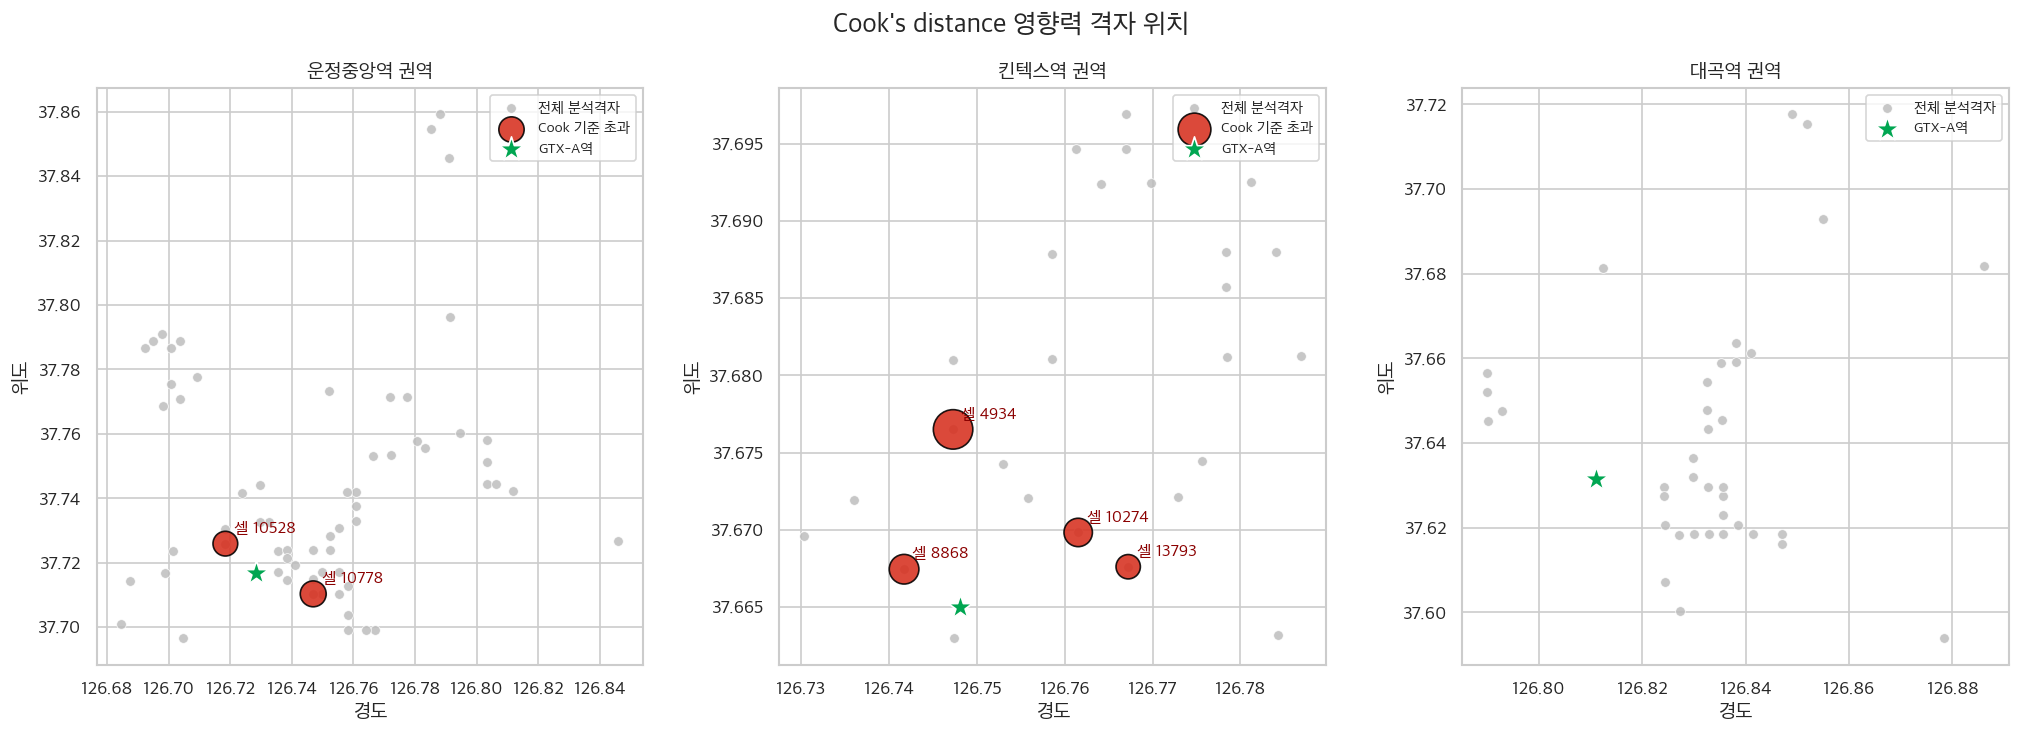

In [15]:
# 역 권역별 정적 위치도: 회색은 전체 분석격자, 빨간색은 영향력 격자
station_coordinates = {
    '운정중앙': (126.728330, 37.716670),
    '킨텍스': (126.748060, 37.665000),
    '대곡': (126.811024, 37.631626),
}
station_order = ['운정중앙', '킨텍스', '대곡']
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2))
for ax, station in zip(axes, station_order):
    region = sample[sample['nearest_station'].astype(str) == station]
    selected = influence_detail[influence_detail['nearest_station'].astype(str) == station]
    ax.scatter(
        region['중심점 경도'], region['중심점 위도'],
        s=34, color='#BDBDBD', edgecolor='white', linewidth=.5,
        alpha=.85, label='전체 분석격자', zorder=1,
    )
    if len(selected):
        marker_sizes = 180 + 950 * selected["Cook's distance"]
        ax.scatter(
            selected['중심점 경도'], selected['중심점 위도'],
            s=marker_sizes, color='#D7301F', edgecolor='black', linewidth=1,
            alpha=.88, label='Cook 기준 초과', zorder=3,
        )
        for _, row in selected.iterrows():
            ax.annotate(
                f"셀 {int(row[ID])}",
                (row['중심점 경도'], row['중심점 위도']),
                xytext=(5, 6), textcoords='offset points',
                fontsize=10, fontweight='bold', color='#8B0000', zorder=4,
            )
    station_lon, station_lat = station_coordinates[station]
    ax.scatter(
        station_lon, station_lat, marker='*', s=230,
        color='#00A651', edgecolor='white', linewidth=1,
        label='GTX-A역', zorder=5,
    )
    ax.set_title(f'{station}역 권역')
    ax.set_xlabel('경도'); ax.set_ylabel('위도')
    ax.ticklabel_format(style='plain', useOffset=False)
    ax.legend(loc='best', fontsize=9)
fig.suptitle("Cook's distance 영향력 격자 위치", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [16]:
# 클릭 가능한 OpenStreetMap 기반 확인 지도
import folium
from folium.plugins import Fullscreen

center = [sample['중심점 위도'].mean(), sample['중심점 경도'].mean()]
influence_map = folium.Map(location=center, zoom_start=11, tiles='CartoDB positron')
Fullscreen(position='topright').add_to(influence_map)

# GTX-A역
for station, (lon, lat) in station_coordinates.items():
    folium.Marker(
        [lat, lon], tooltip=f'{station}역',
        popup=f'GTX-A {station}역',
        icon=folium.Icon(color='green', icon='star'),
    ).add_to(influence_map)

# 전체 126개 격자의 중심점
for _, row in sample.iterrows():
    folium.CircleMarker(
        [row['중심점 위도'], row['중심점 경도']],
        radius=2.5, color='#777777', fill=True,
        fill_opacity=.45, weight=.5,
        tooltip=f"셀 {int(row[ID])}",
    ).add_to(influence_map)

# 영향력 격자: 250m 격자의 중심에서 약 125m 반경을 함께 표시
for _, row in influence_detail.iterrows():
    popup_html = f"""
    <b>셀 {int(row[ID])}</b><br>
    권역: {row['nearest_station']}<br>
    2024 승차: {row['board_2024_all']:.0f}명<br>
    2025 승차: {row['board_2025_all']:.0f}명<br>
    실제 변화: {row['change_all']:.0f}명<br>
    모형 예측: {row['모형 예측 변화량']:.1f}명<br>
    잔차: {row['잔차']:.1f}명<br>
    보행시간: {row['walk_min']:.1f}분<br>
    연면적: {row[FLOOR]:.2f}천㎡<br>
    주거비율: {row[RESIDENTIAL]:.1f}%<br>
    Cook's D: {row["Cook's distance"]:.3f}
    """
    folium.Circle(
        [row['중심점 위도'], row['중심점 경도']], radius=125,
        color='#D7301F', fill=True, fill_color='#FB6A4A',
        fill_opacity=.30, weight=2,
        tooltip=f"영향력 셀 {int(row[ID])}",
        popup=folium.Popup(popup_html, max_width=330),
    ).add_to(influence_map)

folium.LayerControl().add_to(influence_map)
display(influence_map)

### 영향력 격자 해석 시 주의사항

- Cook's distance가 크다는 사실은 해당 격자가 잘못됐다는 뜻이 아니라, 그 격자의 수요 변화가 회귀계수에 큰 영향을 준다는 뜻이다.
- 특히 2024년 승차규모가 매우 큰 격자는 절대 변화량도 커지기 쉬우므로, 기초 승차규모와 실제 시설을 함께 확인한다.
- 시설명을 붙일 때는 “킨텍스역 권역”과 “KINTEX 전시장 자체”를 구분한다. 해당 격자가 시설 경계와 실제로 중첩되는지 확인한 뒤 사례명을 사용한다.
- 주 분석에서는 6개 격자를 유지하고, 역 제외 분석 및 향후 영향력 격자 제외 민감도 분석으로 결론의 안정성을 확인한다.

## 12. 개통 전 승차규모 추가 민감도 분석

종속변수가 절대 변화량이므로 2024년 승차인원이 많은 격자는 감소할 수 있는 절대 규모도 크다. 영향력 격자도 대체로 기초 승차규모가 크므로 `log(1+2024년 승차인원)`을 추가한 민감도 모형을 비교한다.

다만 변화량 안에 2024년 승차인원이 이미 포함되므로 이 변수의 추가는 수학적 결합과 평균회귀 문제를 만들 수 있다. 따라서 기초 승차규모 통제모형은 주 모형의 자동 대체가 아니라, 보행시간·연면적·주거지역 결과가 기초 수요규모를 통제해도 유지되는지 확인하는 강건성 분석으로 사용한다.

In [17]:
sample_baseline = sample.copy()
sample_baseline['log_pre_boarding'] = np.log1p(sample_baseline['board_2024_all'])
BASELINE_FEATURES = FINAL_FEATURES + ['log_pre_boarding']
X_baseline = sm.add_constant(sample_baseline[BASELINE_FEATURES].astype(float), has_constant='add')
baseline_fit = sm.OLS(
    sample_baseline['change_all'].astype(float), X_baseline
).fit(cov_type='HC3')

baseline_comparison = pd.DataFrame([
    {
        '모형': '부분 로그변환 주 모형', '표본 수': int(final_fit.nobs),
        '수정 R²': final_fit.rsquared_adj, 'AIC': final_fit.aic,
        '보행시간 계수': final_fit.params['log_walk'], '보행시간 p값': final_fit.pvalues['log_walk'],
        '연면적 계수': final_fit.params['log_floor'], '연면적 p값': final_fit.pvalues['log_floor'],
        '주거지역 계수': final_fit.params[RESIDENTIAL], '주거지역 p값': final_fit.pvalues[RESIDENTIAL],
        '기초 승차 계수': np.nan, '기초 승차 p값': np.nan,
    },
    {
        '모형': '+ log(1+2024년 승차인원)', '표본 수': int(baseline_fit.nobs),
        '수정 R²': baseline_fit.rsquared_adj, 'AIC': baseline_fit.aic,
        '보행시간 계수': baseline_fit.params['log_walk'], '보행시간 p값': baseline_fit.pvalues['log_walk'],
        '연면적 계수': baseline_fit.params['log_floor'], '연면적 p값': baseline_fit.pvalues['log_floor'],
        '주거지역 계수': baseline_fit.params[RESIDENTIAL], '주거지역 p값': baseline_fit.pvalues[RESIDENTIAL],
        '기초 승차 계수': baseline_fit.params['log_pre_boarding'],
        '기초 승차 p값': baseline_fit.pvalues['log_pre_boarding'],
    },
])
display(baseline_comparison.round(4))

baseline_ci = baseline_fit.conf_int().loc[BASELINE_FEATURES]
baseline_coefficients = pd.DataFrame({
    '변수': [LABELS.get(v, 'log(1+2024년 승차인원)') for v in BASELINE_FEATURES],
    '계수': baseline_fit.params.loc[BASELINE_FEATURES].values,
    'HC3 표준오차': baseline_fit.bse.loc[BASELINE_FEATURES].values,
    'p값': baseline_fit.pvalues.loc[BASELINE_FEATURES].values,
    '95% CI 하한': baseline_ci[0].values,
    '95% CI 상한': baseline_ci[1].values,
})
display(baseline_coefficients.round(4))

,모형,표본 수,수정 R²,AIC,보행시간 계수,보행시간 p값,연면적 계수,연면적 p값,주거지역 계수,주거지역 p값,기초 승차 계수,기초 승차 p값
0,부분 로그변환 주 모형,126,0.3074,1642.4744,148.8107,0.0000,-72.1137,0.0618,1.6974,0.0249,NaN,NaN
1,+ log(1+2024년 승차인원),126,0.5335,1593.6169,60.5778,0.0057,-25.9593,0.3436,1.5058,0.0145,-74.8404,0.0


,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한
0,log(1+GTX역 보행시간),60.5778,21.9232,0.0057,17.6090,103.5465
1,20~50대 인구(명),0.0100,0.0312,0.7480,-0.0511,0.0711
2,log(1+건축물 연면적),-25.9593,27.4119,0.3436,-79.6857,27.7671
3,주거지역 비율(%),1.5058,0.6157,0.0145,0.2991,2.7125
4,GTX 경쟁 목적지 비율(%),-0.3511,0.4674,0.4525,-1.2673,0.5650
5,평균 버스 통행시간(분),0.1163,1.2356,0.9250,-2.3053,2.5380
6,IC 도로거리(km),-3.8819,3.9245,0.3226,-11.5738,3.8099
7,log(1+2024년 승차인원),-74.8404,14.1584,0.0000,-102.5903,-47.0905


### 기초 승차규모 통제 결과의 의미

- 기초 승차규모를 추가하면 수정 R²가 크게 증가하므로 절대 변화량은 개통 전 승차규모와 강하게 관련된다.
- 보행시간의 양의 계수가 유지되면 GTX역에서 가까울수록 감소폭이 크다는 결과는 기초 승차규모를 통제해도 남는다는 뜻이다.
- 연면적 효과가 약해지면 총연면적 자체보다 대규모 승차거점과의 결합이 기존 연면적 결과에 반영되었을 가능성이 있다.
- 주거지역 비율 결과는 유지 여부를 확인하되, 영향력 격자 제외 분석과 함께 해석한다.
- 기초 승차규모 계수는 변화량의 정의와 기계적으로 연결되므로 독립적인 인과효과로 해석하지 않는다.

## 13. 현재 모형의 판단

- **주 분석:** 126개 전체의 부분 로그변환 변화량 OLS(HC3)
- **강건성 분석:** 역 고정효과, 역 하나씩 제외, Cook 영향력 격자 확인, 기초 승차규모 추가
- **안정적인 결론:** 보행시간 효과
- **탐색적인 결론:** 건축물 연면적과 주거지역 비율

설명변수를 더 추가할 때는 현장답사에서 반복적으로 확인되고, GTX-B·C에서도 개통 전에 동일한 기준으로 구축할 수 있는 변수만 사용한다. 126개 표본에서 유의성을 높이기 위한 사후 변수 추가는 피한다.

## 14. ANCOVA: 2025년 승차인원에 대한 기초 승차규모 통제

변화량에 2024년 승차인원을 다시 넣으면 변화량 정의 안에 이미 포함된 기초값 때문에 기계적 상관과 평균회귀 문제가 생길 수 있다. 따라서 별도 ANCOVA에서는 종속변수를 **2025년 승차인원**으로 바꾸고, **2024년 승차인원**을 공변량으로 통제한다.

\[
Boarding_{2025,i}=\alpha+\rho Boarding_{2024,i}+\beta X_i+\epsilon_i
\]

- 변화량 OLS 질문: 어느 격자에서 절대 감소량이 컸는가?
- ANCOVA 질문: 개통 전 승차규모가 같은 격자끼리 비교할 때 개통 후 승차인원의 차이를 무엇이 설명하는가?

두 모형은 연구 질문이 다르므로 하나의 p값만으로 다른 모형을 폐기하지 않고 함께 비교한다.

In [18]:
# 원 단위 ANCOVA: 2025년 승차인원 ~ 2024년 승차인원 + 지역·교통 특성
ANCOVA_FEATURES = FINAL_FEATURES + ['board_2024_all']
ancova_sample = sample.dropna(subset=['board_2025_all'] + ANCOVA_FEATURES).copy()
X_ancova = sm.add_constant(ancova_sample[ANCOVA_FEATURES].astype(float), has_constant='add')
ancova_fit = sm.OLS(
    ancova_sample['board_2025_all'].astype(float), X_ancova
).fit(cov_type='HC3')
print(ancova_fit.summary())

ANCOVA_LABELS = {**LABELS, 'board_2024_all': '2024년 승차인원(명)'}
ancova_ci = ancova_fit.conf_int().loc[ANCOVA_FEATURES]
ancova_coefficients = pd.DataFrame({
    '변수': [ANCOVA_LABELS[v] for v in ANCOVA_FEATURES],
    '계수': ancova_fit.params.loc[ANCOVA_FEATURES].values,
    'HC3 표준오차': ancova_fit.bse.loc[ANCOVA_FEATURES].values,
    'p값': ancova_fit.pvalues.loc[ANCOVA_FEATURES].values,
    '95% CI 하한': ancova_ci[0].values,
    '95% CI 상한': ancova_ci[1].values,
})
ancova_coefficients['유의성'] = np.select(
    [ancova_coefficients['p값'] < .01, ancova_coefficients['p값'] < .05,
     ancova_coefficients['p값'] < .10],
    ['***', '**', '*'], default=''
)
display(ancova_coefficients.round(4))
display(pd.DataFrame([{
    '표본 수': int(ancova_fit.nobs), 'R²': ancova_fit.rsquared,
    '수정 R²': ancova_fit.rsquared_adj, '모형 p값': float(ancova_fit.f_pvalue),
    'AIC': ancova_fit.aic, 'BIC': ancova_fit.bic,
}]).round(4))

ancova_vif = pd.DataFrame({
    '변수': [ANCOVA_LABELS[v] for v in ANCOVA_FEATURES],
    'VIF': [variance_inflation_factor(X_ancova.to_numpy(), X_ancova.columns.get_loc(v))
            for v in ANCOVA_FEATURES],
}).sort_values('VIF', ascending=False)
print('===== ANCOVA VIF =====')
display(ancova_vif.round(3))

                            OLS Regression Results                            
Dep. Variable:         board_2025_all   R-squared:                       0.942
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     80.61
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           5.66e-44
Time:                        15:11:35   Log-Likelihood:                -558.84
No. Observations:                 126   AIC:                             1136.
Df Residuals:                     117   BIC:                             1161.
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -9.8033     37.666     

,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한,유의성
0,log(1+GTX역 보행시간),5.3394,7.9379,0.5012,-10.2187,20.8974,
1,20~50대 인구(명),0.0105,0.0120,0.3841,-0.0131,0.0340,
2,log(1+건축물 연면적),0.9976,4.7680,0.8343,-8.3474,10.3426,
3,주거지역 비율(%),-0.0664,0.1673,0.6914,-0.3943,0.2615,
4,GTX 경쟁 목적지 비율(%),-0.1111,0.0659,0.0919,-0.2403,0.0181,*
5,평균 버스 통행시간(분),-0.2252,0.1578,0.1535,-0.5345,0.0841,
6,IC 도로거리(km),-0.7660,0.9287,0.4095,-2.5861,1.0542,
7,2024년 승차인원(명),0.3040,0.0132,0.0000,0.2781,0.3299,***


,표본 수,R²,수정 R²,모형 p값,AIC,BIC
0,126,0.9417,0.9377,0.0,1135.6712,1161.1977


,변수,VIF
1,20~50대 인구(명),2.579
2,log(1+건축물 연면적),2.369
0,log(1+GTX역 보행시간),2.118
3,주거지역 비율(%),1.992
7,2024년 승차인원(명),1.530
6,IC 도로거리(km),1.426
4,GTX 경쟁 목적지 비율(%),1.143
5,평균 버스 통행시간(분),1.048


### 로그 ANCOVA 민감도 분석

승차인원은 0 이상이고 오른쪽 꼬리가 길기 때문에 `log(1+2024년 승차인원)`과 `log(1+2025년 승차인원)`을 사용한 모형도 보조적으로 확인한다. 종속변수의 척도가 달라지므로 원 단위 ANCOVA와 로그 ANCOVA의 AIC를 직접 비교하지 않는다.

In [19]:
ancova_log_sample = sample.copy()
ancova_log_sample['log_pre_boarding'] = np.log1p(ancova_log_sample['board_2024_all'])
ancova_log_sample['log_post_boarding'] = np.log1p(ancova_log_sample['board_2025_all'])
LOG_ANCOVA_FEATURES = FINAL_FEATURES + ['log_pre_boarding']
X_log_ancova = sm.add_constant(
    ancova_log_sample[LOG_ANCOVA_FEATURES].astype(float), has_constant='add'
)
log_ancova_fit = sm.OLS(
    ancova_log_sample['log_post_boarding'].astype(float), X_log_ancova
).fit(cov_type='HC3')

LOG_ANCOVA_LABELS = {**LABELS, 'log_pre_boarding': 'log(1+2024년 승차인원)'}
log_ancova_ci = log_ancova_fit.conf_int().loc[LOG_ANCOVA_FEATURES]
log_ancova_coefficients = pd.DataFrame({
    '변수': [LOG_ANCOVA_LABELS[v] for v in LOG_ANCOVA_FEATURES],
    '계수': log_ancova_fit.params.loc[LOG_ANCOVA_FEATURES].values,
    'HC3 표준오차': log_ancova_fit.bse.loc[LOG_ANCOVA_FEATURES].values,
    'p값': log_ancova_fit.pvalues.loc[LOG_ANCOVA_FEATURES].values,
    '95% CI 하한': log_ancova_ci[0].values,
    '95% CI 상한': log_ancova_ci[1].values,
})
log_ancova_coefficients['유의성'] = np.select(
    [log_ancova_coefficients['p값'] < .01, log_ancova_coefficients['p값'] < .05,
     log_ancova_coefficients['p값'] < .10],
    ['***', '**', '*'], default=''
)
display(log_ancova_coefficients.round(4))
display(pd.DataFrame([{
    '표본 수': int(log_ancova_fit.nobs), 'R²': log_ancova_fit.rsquared,
    '수정 R²': log_ancova_fit.rsquared_adj, '모형 p값': float(log_ancova_fit.f_pvalue),
    'AIC': log_ancova_fit.aic, 'BIC': log_ancova_fit.bic,
}]).round(4))

,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한,유의성
0,log(1+GTX역 보행시간),0.1126,0.1072,0.2932,-0.0974,0.3227,
1,20~50대 인구(명),0.0000,0.0001,0.7610,-0.0002,0.0003,
2,log(1+건축물 연면적),0.0734,0.0894,0.4120,-0.1019,0.2486,
3,주거지역 비율(%),-0.0006,0.0020,0.7611,-0.0046,0.0034,
4,GTX 경쟁 목적지 비율(%),-0.0039,0.0018,0.0292,-0.0075,-0.0004,**
5,평균 버스 통행시간(분),-0.0038,0.0050,0.4390,-0.0135,0.0059,
6,IC 도로거리(km),-0.0159,0.0211,0.4508,-0.0573,0.0255,
7,log(1+2024년 승차인원),0.8283,0.0383,0.0000,0.7532,0.9034,***


,표본 수,R²,수정 R²,모형 p값,AIC,BIC
0,126,0.8837,0.8757,0.0,179.1729,204.6994


In [20]:
# 핵심 변수의 세 모형 비교: 계수의 크기는 종속변수 척도가 달라 직접 비교하지 않는다.
model_question_comparison = pd.DataFrame([
    {
        '모형': '변화량 OLS', '종속변수': '2025-2024 승차인원',
        '보행시간 p값': final_fit.pvalues['log_walk'],
        '연면적 p값': final_fit.pvalues['log_floor'],
        '주거지역 p값': final_fit.pvalues[RESIDENTIAL],
        '경쟁목적지 p값': final_fit.pvalues['competing_share'],
        '기초 승차 p값': np.nan,
    },
    {
        '모형': '원 단위 ANCOVA', '종속변수': '2025 승차인원',
        '보행시간 p값': ancova_fit.pvalues['log_walk'],
        '연면적 p값': ancova_fit.pvalues['log_floor'],
        '주거지역 p값': ancova_fit.pvalues[RESIDENTIAL],
        '경쟁목적지 p값': ancova_fit.pvalues['competing_share'],
        '기초 승차 p값': ancova_fit.pvalues['board_2024_all'],
    },
    {
        '모형': '로그 ANCOVA', '종속변수': 'log(1+2025 승차인원)',
        '보행시간 p값': log_ancova_fit.pvalues['log_walk'],
        '연면적 p값': log_ancova_fit.pvalues['log_floor'],
        '주거지역 p값': log_ancova_fit.pvalues[RESIDENTIAL],
        '경쟁목적지 p값': log_ancova_fit.pvalues['competing_share'],
        '기초 승차 p값': log_ancova_fit.pvalues['log_pre_boarding'],
    },
])
display(model_question_comparison.round(4))

,모형,종속변수,보행시간 p값,연면적 p값,주거지역 p값,경쟁목적지 p값,기초 승차 p값
0,변화량 OLS,2025-2024 승차인원,0.0000,0.0618,0.0249,0.0866,NaN
1,원 단위 ANCOVA,2025 승차인원,0.5012,0.8343,0.6914,0.0919,0.0
2,로그 ANCOVA,log(1+2025 승차인원),0.2932,0.4120,0.7611,0.0292,0.0


### ANCOVA 해석 원칙

- 원 단위 ANCOVA에서 2024년 승차인원 계수는 다른 조건이 같을 때 개통 전 승차인원 1명 차이가 개통 후 승차인원과 얼마나 관련되는지를 나타낸다.
- 기초 승차규모 통제 후 보행시간·연면적·주거지역 효과가 약해지면, 변화량 OLS에서 관찰된 관계의 상당 부분이 원래 수요가 큰 격자의 큰 절대 감소와 연결되어 있었다는 의미다.
- 로그 ANCOVA는 비례적인 개통 후 수요 유지 관계를 보는 보조모형이다.
- 변화량 OLS는 공간적 절대 감소를 설명하는 기술모형으로, ANCOVA는 기초 수요가 동일하다는 조건에서 개통 후 수요를 비교하는 강건성 모형으로 제시한다.

## 15. 심사 대응 보완: 영향력 격자 제외 재추정

Cook's distance `4/N` 기준을 넘은 6개 격자를 제외한 뒤 주모형을 동일한 변수와 HC3 표준오차로 재추정한다. 6개 격자는 데이터 오류로 판정된 것이 아니므로 전체 126개 모형을 주 결과로 유지하며, 제외 모형은 표본 민감도 분석으로만 사용한다.

In [21]:
influential_ids = influence_detail[ID].astype(int).tolist()
reduced_sample = sample[~sample[ID].astype(int).isin(influential_ids)].copy()
X_reduced = sm.add_constant(reduced_sample[FINAL_FEATURES].astype(float), has_constant='add')
reduced_fit = sm.OLS(
    reduced_sample['change_all'].astype(float), X_reduced
).fit(cov_type='HC3')

sensitivity_rows = []
for model_name, fitted in [
    ('전체 126개', final_fit),
    ('영향력 6개 제외', reduced_fit),
]:
    for variable in FINAL_FEATURES:
        ci_low, ci_high = fitted.conf_int().loc[variable]
        sensitivity_rows.append({
            '모형': model_name,
            '변수': LABELS[variable],
            '계수': fitted.params[variable],
            'HC3 표준오차': fitted.bse[variable],
            'p값': fitted.pvalues[variable],
            '95% CI 하한': ci_low,
            '95% CI 상한': ci_high,
        })
influence_sensitivity_full = pd.DataFrame(sensitivity_rows)
print('===== 전체 변수 영향력 격자 포함·제외 비교 =====')
display(influence_sensitivity_full.round(4))

key_variables = ['log_walk', 'log_floor', RESIDENTIAL]
key_rows = []
for variable in key_variables:
    row = {'변수': LABELS[variable]}
    for prefix, fitted in [('전체', final_fit), ('6개 제외', reduced_fit)]:
        row[f'{prefix} 계수'] = fitted.params[variable]
        row[f'{prefix} HC3 표준오차'] = fitted.bse[variable]
        row[f'{prefix} p값'] = fitted.pvalues[variable]
    key_rows.append(row)
print('===== 핵심 변수 비교 =====')
display(pd.DataFrame(key_rows).round(4))

sensitivity_model_fit = pd.DataFrame([
    {'모형': '전체 126개', '표본 수': int(final_fit.nobs),
     'R²': final_fit.rsquared, '수정 R²': final_fit.rsquared_adj,
     'AIC': final_fit.aic, 'BIC': final_fit.bic},
    {'모형': '영향력 6개 제외', '표본 수': int(reduced_fit.nobs),
     'R²': reduced_fit.rsquared, '수정 R²': reduced_fit.rsquared_adj,
     'AIC': reduced_fit.aic, 'BIC': reduced_fit.bic},
])
display(sensitivity_model_fit.round(4))

===== 전체 변수 영향력 격자 포함·제외 비교 =====
===== 핵심 변수 비교 =====


,모형,변수,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한
0,전체 126개,log(1+GTX역 보행시간),148.8107,32.9488,0.0000,84.2322,213.3892
1,전체 126개,20~50대 인구(명),0.0370,0.0364,0.3094,-0.0344,0.1084
2,전체 126개,log(1+건축물 연면적),-72.1137,38.6079,0.0618,-147.7837,3.5563
3,전체 126개,주거지역 비율(%),1.6974,0.7567,0.0249,0.2142,3.1806
4,전체 126개,GTX 경쟁 목적지 비율(%),-1.1164,0.6514,0.0866,-2.3931,0.1603
5,전체 126개,평균 버스 통행시간(분),-0.1797,1.0542,0.8646,-2.2459,1.8864
6,전체 126개,IC 도로거리(km),-3.2943,3.8673,0.3943,-10.8740,4.2854
7,영향력 6개 제외,log(1+GTX역 보행시간),85.4708,26.3982,0.0012,33.7312,137.2104
8,영향력 6개 제외,20~50대 인구(명),-0.0051,0.0305,0.8663,-0.0649,0.0546
9,영향력 6개 제외,log(1+건축물 연면적),-11.8679,14.0812,0.3993,-39.4666,15.7307


,변수,전체 계수,전체 HC3 표준오차,전체 p값,6개 제외 계수,6개 제외 HC3 표준오차,6개 제외 p값
0,log(1+GTX역 보행시간),148.8107,32.9488,0.0000,85.4708,26.3982,0.0012
1,log(1+건축물 연면적),-72.1137,38.6079,0.0618,-11.8679,14.0812,0.3993
2,주거지역 비율(%),1.6974,0.7567,0.0249,0.3886,0.4739,0.4123


,모형,표본 수,R²,수정 R²,AIC,BIC
0,전체 126개,126,0.3462,0.3074,1642.4744,1665.1646
1,영향력 6개 제외,120,0.3212,0.2788,1404.6311,1426.9311


### 영향력 민감도 해석

보행시간 계수는 영향력 격자 제외 후에도 양의 방향과 통계적 유의성이 유지되는지 확인한다. 다만 전체 표본과 제외 표본의 계수 크기가 달라지면 효과 크기까지 안정적이라고 표현하지 않고, **계수의 양의 방향이 표본구성 변화에도 유지되었다**고 제한하여 서술한다. 연면적과 주거지역 비율의 유의성이 사라지면 해당 결과는 일부 대규모 감소 격자에 민감한 탐색적 관계로 해석한다.

## 16. 로그 ANCOVA 경쟁 목적지 비율의 효과크기

로그 ANCOVA의 종속변수는 `log(1+2025년 승차인원)`이다. 따라서 경쟁 목적지 비율 계수는 퍼센트 차이로 변환해 제시한다. 아래 값은 조건부 관련성이며 인과효과가 아니다.

In [22]:
competition_beta = log_ancova_fit.params['competing_share']
competition_se = log_ancova_fit.bse['competing_share']
competition_ci = log_ancova_fit.conf_int().loc['competing_share']

def log_coef_to_percent(beta, delta):
    return 100 * (np.exp(beta * delta) - 1)

competition_effect = pd.DataFrame([
    {
        '증가 단위': '경쟁 목적지 비율 1%p 증가',
        '예상 차이(%)': log_coef_to_percent(competition_beta, 1),
        '95% CI 하한(%)': log_coef_to_percent(competition_ci[0], 1),
        '95% CI 상한(%)': log_coef_to_percent(competition_ci[1], 1),
    },
    {
        '증가 단위': '경쟁 목적지 비율 10%p 증가',
        '예상 차이(%)': log_coef_to_percent(competition_beta, 10),
        '95% CI 하한(%)': log_coef_to_percent(competition_ci[0], 10),
        '95% CI 상한(%)': log_coef_to_percent(competition_ci[1], 10),
    },
])
competition_statistics = pd.DataFrame([{
    '계수': competition_beta,
    'HC3 표준오차': competition_se,
    'p값': log_ancova_fit.pvalues['competing_share'],
    '95% CI 하한': competition_ci[0],
    '95% CI 상한': competition_ci[1],
}])
display(competition_statistics.round(5))
display(competition_effect.round(3))

,계수,HC3 표준오차,p값,95% CI 하한,95% CI 상한
0,-0.00395,0.00181,0.02919,-0.0075,-0.0004


,증가 단위,예상 차이(%),95% CI 하한(%),95% CI 상한(%)
0,경쟁 목적지 비율 1%p 증가,-0.394,-0.747,-0.040
1,경쟁 목적지 비율 10%p 증가,-3.872,-7.223,-0.399


## 17. 최종 보고 체계와 표현

1. **주 분석:** 절대 승차인원 변화량 OLS
2. **영향력 민감도 분석:** 영향력 격자 6개 포함·제외 비교
3. **baseline 조정 보조분석:** 원 단위 ANCOVA와 로그 ANCOVA
4. **공간 사례분석:** 영향력 격자의 공간적 특성 및 현장 확인

### 권장 종합 결론

> 절대 승차인원 변화량을 분석한 주모형에서는 GTX역과 가까운 격자일수록 광역버스 승차인원 감소량이 크게 나타났으며, 보행시간 계수의 양의 방향은 역 권역 통제 및 영향력 격자에 대한 민감도 분석에서도 유지되었다. 다만 계수 크기는 표본구성에 따라 차이를 보였다. 개통 전 승차규모를 통제한 ANCOVA에서는 보행시간의 독립적인 관련성이 통계적으로 확인되지 않았다. 따라서 GTX역 인근에서 절대 감소량이 크게 나타난 공간적 패턴은 확인되지만, 이를 GTX 접근성만의 독립적인 효과로 해석하기는 어렵다. 로그 ANCOVA에서는 경쟁 목적지 비율이 개통 후 승차인원과 음의 관련성을 보였으며, 이는 조건부 관련성으로 해석한다.

### 모형 진단에 관한 제한

HC3는 이분산에 대한 표준오차를 보정하지만 RESET 기각, 영향력 관측치 및 공간적 자기상관 가능성을 해결하지 않는다. 따라서 주모형을 완전히 설정된 인과모형으로 표현하지 않고 조건부 연관성을 분석하는 탐색적 공간모형으로 제시한다. 하루 합성자료, 3개 GTX-A역, 통제집단 부재로 인해 결과의 외적·인과적 일반화에는 한계가 있다.